## Module 3: Computational Drug Discovery Project 

Complete the sections below as a team. Remove the word “Template” only if it appears in the final notebook title.

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 
Provide a brief (<200 word) background of obesity, available treatments, and especially why improved treatments are needed. Your answers may include for example: 
Prevalence & incidence, Symptoms, Diagnosis, Standard of care treatments (& reimbursement), Disease progression & prognosis, Biological mechanisms (anatomy, organ physiology, cell & molecular physiology), Clinical Trials/next-gen therapies.

Please provide citations and/or hyperlinks to where you obtained information (including AI) for each of the bullet points.

### Background of obesity

Obesity is a chronic disease involving excess adiposity. Body-mass index (BMI; kg/m²) is a practical screening measure, but should be interpreted with a person’s clinical risks. In 2024, an estimated 1.1 billion people worldwide were living with obesity, and since 1990, adult obesity has more than doubled. [WHO](https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight)

Obesity arises from interacting biological, behavioural, social, and environmental determinants and raises the risk of type 2 diabetes, cardiovascular disease, liver and kidney disease, and several cancers. [WHO](https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight) Standard care begins with individualized nutrition, physical-activity, and behavioural support. Anti-obesity medicines and metabolic/bariatric surgery are additional options when appropriate. [NIDDK](https://www.niddk.nih.gov/health-information/weight-management/adult-overweight-obesity/treatment/) GLP-1 receptor agonists are an important progression in combatting the disease, but medication choice must consider benefit, adverse effects, and cost, and insurance coverage is variable. Weight is commonly regained after medication is stopped. [NIDDK](https://www.niddk.nih.gov/health-information/weight-management/prescription-medications-treat-overweight-obesity) Better therapies are needed to provide more durable and accessible treatment alongside lifestyle care.


## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

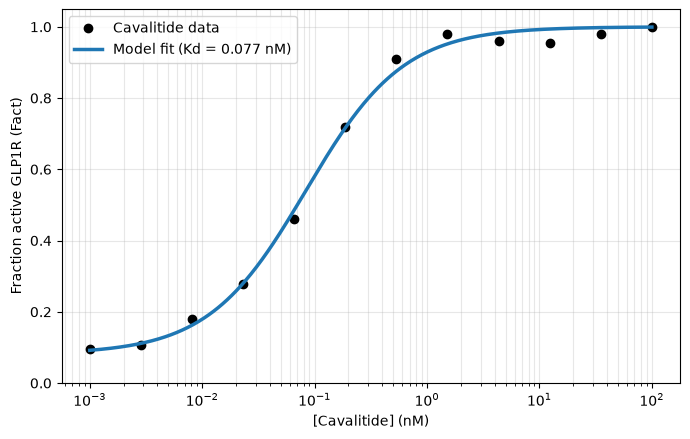

Fitted Cavalitide Kd: 0.077 nM
Goodness of fit: R² = 0.997; SSE = 0.0052


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Competitive co-agonist model used in the Module 3 semaglutide example.
def fraction_active(glp1_nM, cavalitide_nM, kd_glp1_nM, kd_cavalitide_nM):
    return ((kd_cavalitide_nM * glp1_nM) + (kd_glp1_nM * cavalitide_nM)) / (
        (kd_glp1_nM * kd_cavalitide_nM)
        + (kd_cavalitide_nM * glp1_nM)
        + (kd_glp1_nM * cavalitide_nM)
    )

# Works whether the notebook is run from this folder or from the repository root.
data_path = Path("cavalitide_data.csv")
if not data_path.exists():
    data_path = Path("Final Assignment/cavalitide_data.csv")

cavalitide_nM, fact_observed = np.loadtxt(data_path, delimiter=",", skiprows=1).T
kd_glp1_nM = 0.17
glp1_fasting_nM = 0.015

# One-parameter least-squares fit. A dense log-spaced grid avoids an extra dependency.
kd_candidates_nM = np.logspace(-4, 2, 100_000)
predictions = fraction_active(
    glp1_fasting_nM, cavalitide_nM[:, None], kd_glp1_nM, kd_candidates_nM[None, :]
)
sse = np.sum((fact_observed[:, None] - predictions) ** 2, axis=0)
kd_cavalitide_nM = kd_candidates_nM[np.argmin(sse)]
fact_fitted = fraction_active(
    glp1_fasting_nM, cavalitide_nM, kd_glp1_nM, kd_cavalitide_nM
)
r_squared = 1 - np.sum((fact_observed - fact_fitted) ** 2) / np.sum(
    (fact_observed - np.mean(fact_observed)) ** 2
)

x_plot = np.logspace(-3, 2, 500)
plt.figure(figsize=(7, 4.5))
plt.semilogx(cavalitide_nM, fact_observed, "o", color="black", label="Cavalitide data")
plt.semilogx(
    x_plot,
    fraction_active(glp1_fasting_nM, x_plot, kd_glp1_nM, kd_cavalitide_nM),
    linewidth=2.5,
    label=f"Model fit (Kd = {kd_cavalitide_nM:.3f} nM)",
)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active GLP1R (Fact)")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Fitted Cavalitide Kd: {kd_cavalitide_nM:.3f} nM")
print(f"Goodness of fit: R² = {r_squared:.3f}; SSE = {np.min(sse):.4f}")


### Task 1 interpretation

The model fit gives Kd(Cavalitide) = 0.077 nM (R² = 0.997; SSE = 0.0052). This is about five times lower than the semaglutide Kd of 0.38 nM used in the previous example. Because a lower Kd corresponds to tighter receptor binding in this model, Cavalitide should reach a given GLP1R activation at a lower free concentration, which is an advantage. However, Kd alone does not establish a superior drug, since other factors like effictivy and absorption are very important.


## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

*OpenAI Codex was used to help draft the disease-background summary and to implement the Task 1 receptor-binding fit and plot. The group should review the sources, calculations, and wording before submission.*


## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

1. World Health Organization. [Obesity and overweight](https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight). Accessed 2026-11-16.
2. National Institute of Diabetes and Digestive and Kidney Diseases. [Treatment for Overweight & Obesity](https://www.niddk.nih.gov/health-information/weight-management/adult-overweight-obesity/treatment/). Accessed 2026-11-16.
3. National Institute of Diabetes and Digestive and Kidney Diseases. [Prescription Medications to Treat Overweight & Obesity](https://www.niddk.nih.gov/health-information/weight-management/prescription-medications-treat-overweight-obesity). Accessed 2026-11-16.


## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*